# Computing the Spectrum — Interactive Demo

**Topic 9 · Signals and Systems I**

Run the cells in order. Compute and invert a DFT, compare windowing and zero-padding on a pair of close tones, and use a spectrogram to follow a changing signal.

[Topic 9 summary](../theory-summaries/T9-Computing-the-Spectrum.pdf) · [Class slides](../class-slides/T9_Computing_the_Spectrum_Class_Slides.pdf)

In [1]:
from timeit import repeat

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

try:
    import ipywidgets as widgets
except ImportError:
    widgets = None

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
fs = 8192  # Hz

## 1 · DFT and inverse DFT

For $N$ samples, the DFT evaluates the spectrum at $f_k=kf_s/N$ modulo $f_s$. These are equally spaced samples of the discrete-time Fourier transform (DTFT) of the finite record. The complex coefficients carry both magnitude and phase.

$$X[k]=\sum_{n=0}^{N-1} x[n]e^{-j2\pi kn/N},\qquad
x[n]=\frac{1}{N}\sum_{k=0}^{N-1} X[k]e^{j2\pi kn/N}.$$

Both cosines below complete an integer number of cycles in the record. The centered spectrum shows their positive- and negative-frequency peaks. With the plotted normalization $|X[k]|/N$, each peak is half the amplitude of its cosine. Compare the original samples with the inverse DFT and with a reconstruction using the same magnitudes and zero phase.

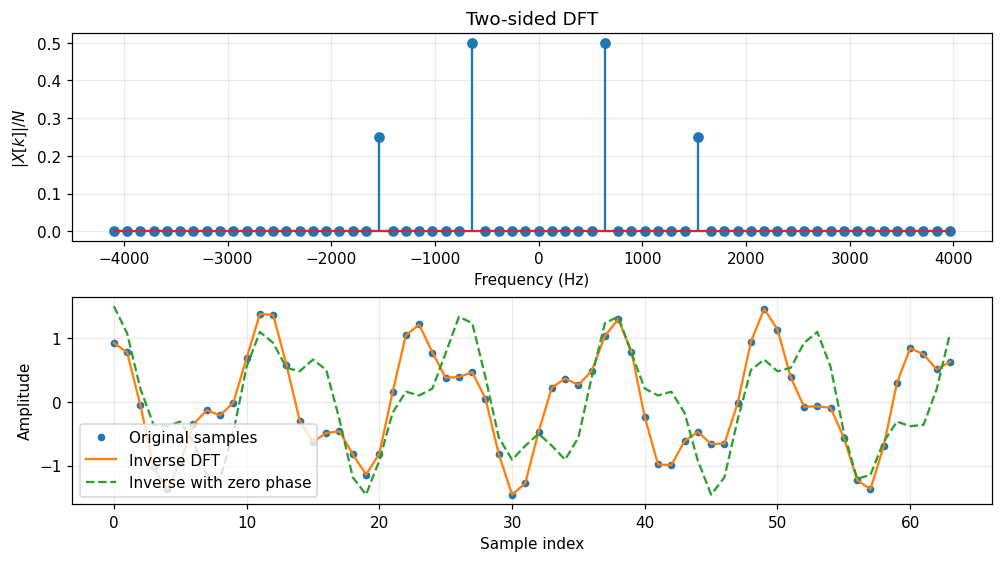

Maximum reconstruction error: 1.97e-14


In [2]:
def dft_basis(size):
    indices = np.arange(size)
    return np.exp(-2j * np.pi * np.outer(indices, indices) / size)


N = 64
n = np.arange(N)
x = np.cos(2 * np.pi * 5 * n / N + 0.8) + 0.5 * np.cos(2 * np.pi * 12 * n / N - 1.1)
basis = dft_basis(N)  # One row per bin k, one column per sample n.
X = basis @ x
recovered = basis.conj().T @ X / N
zero_phase = basis.conj().T @ np.abs(X) / N
f = np.fft.fftshift(np.fft.fftfreq(N, d=1 / fs))

fig, (ax_spectrum, ax_time) = plt.subplots(2, 1, figsize=(9, 5), layout="constrained")
ax_spectrum.stem(f, np.fft.fftshift(np.abs(X)) / N)
ax_spectrum.set(xlabel="Frequency (Hz)", ylabel=r"$|X[k]|/N$", title="Two-sided DFT")
ax_time.plot(n, x, "o", markersize=4, label="Original samples")
ax_time.plot(n, recovered.real, label="Inverse DFT")
ax_time.plot(n, zero_phase.real, "--", label="Inverse with zero phase")
ax_time.set(xlabel="Sample index", ylabel="Amplitude")
ax_time.legend()
plt.show()

print(f"Maximum reconstruction error: {np.max(np.abs(recovered - x)):.2e}")

## 2 · The FFT computes the same DFT

The direct calculation uses $N$ terms for each of $N$ bins, for $O(N^2)$ work. A radix-2 FFT splits the sum into smaller transforms of the even and odd samples and combines their results in $O(N\log N)$ operations. NumPy also supports FFT lengths that are not powers of two.

The direct timings include construction of the exponential matrix. The results depend on the machine, especially for short records.

In [3]:
np.testing.assert_allclose(np.fft.fft(x), X, atol=1e-12)
np.testing.assert_allclose(np.fft.ifft(X), x, atol=1e-12)
print("The FFT and direct DFT agree to numerical precision.")
print(f"{'N':>5} {'Direct DFT (ms)':>17} {'FFT (ms)':>12}")

timings = []
for size in (128, 256, 512, 1024):
    samples = np.cos(2 * np.pi * 700 * np.arange(size) / fs)

    def direct_dft():
        return dft_basis(size) @ samples

    np.testing.assert_allclose(direct_dft(), np.fft.fft(samples), atol=1e-9)
    direct_ms = 1000 * min(repeat(direct_dft, number=1, repeat=3))
    fft_ms = min(repeat(lambda: np.fft.fft(samples), number=1000, repeat=3))
    timings.append((size, direct_ms, fft_ms))
    print(f"{size:5d} {direct_ms:17.3f} {fft_ms:12.4f}")

The FFT and direct DFT agree to numerical precision.
    N   Direct DFT (ms)     FFT (ms)
  128             0.243       0.0032
  256             0.798       0.0036
  512             3.397       0.0047
 1024            13.653       0.0072


## 3 · Windowing, leakage, and frequency resolution

Taking $L$ samples implicitly applies a rectangular window. Hann and Hamming taper the ends of the record, reducing sidelobes at the cost of a wider main lobe. A longer record narrows the main lobe for a given window type.

- Choose **Off-bin tone** and switch windows. Compare the main-lobe width and sidelobe levels. Select **Bin-centered tone** with a rectangular window and look at the unpadded bins.
- Choose **Close pair** with Hann. Compare 128 and 512 samples. The two tones are 48 Hz apart and their lobes overlap strongly in the shorter record.
- Choose **Weak neighbor** at 128 samples. Look near 1320 Hz as you switch from rectangular to Hann. The dashed lines mark the true frequencies.

The plots use one-sided amplitude in dB relative to unit amplitude. Dividing by the sum of the window compensates for the window's gain on a bin-centered sinusoid. The dense FFT grid shows the lobe shape between the unpadded bins.

In [4]:
windows = {"Rectangular": np.ones, "Hann": np.hanning, "Hamming": np.hamming}
tone_sets = {
    "Bin-centered tone": ((1024, 1.0),),
    "Off-bin tone": ((1000, 1.0),),
    "Close pair": ((1000, 1.0), (1048, 1.0)),
    "Weak neighbor": ((1000, 1.0), (1320, 0.025)),
}


def windowed_record(length, window, tones):
    time = np.arange(length) / fs
    samples = sum(a * np.cos(2 * np.pi * f0 * time) for f0, a in tone_sets[tones])
    return time, samples, windows[window](length)


def amplitude_db(windowed, fft_length, window_sum):
    amplitude = np.abs(np.fft.rfft(windowed, n=fft_length, axis=-1)) / window_sum
    # All FFT lengths here are even. Double the positive bins between DC and Nyquist.
    amplitude[..., 1:-1] *= 2
    return 20 * np.log10(np.maximum(amplitude, 1e-6))


def plot_spectrum(ax, windowed, window_sum, fft_length, *style, **kwargs):
    frequencies = np.fft.rfftfreq(fft_length, d=1 / fs)
    ax.plot(frequencies, amplitude_db(windowed, fft_length, window_sum), *style, **kwargs)


def mark_tones(ax, tones):
    for frequency, _ in tone_sets[tones]:
        ax.axvline(frequency, color="0.5", linestyle="--", linewidth=1)


def window_demo(length=128, window="Hann", tones="Off-bin tone"):
    time, samples, weights = windowed_record(length, window, tones)
    tapered = samples * weights
    fig, (ax_time, ax_spectrum) = plt.subplots(2, 1, figsize=(9, 5.5), layout="constrained")
    ax_time.plot(1000 * time, samples, alpha=0.4, label="Original")
    ax_time.plot(1000 * time, tapered, label="Windowed")
    ax_time.plot(1000 * time, weights, "--", label=window)
    ax_time.set(xlabel="Time (ms)", ylabel="Amplitude", title=f"Record: {1000 * length / fs:g} ms")
    ax_time.legend(loc="upper right", ncol=3)

    plot_spectrum(ax_spectrum, tapered, weights.sum(), 8192, label="Dense frequency grid")
    plot_spectrum(ax_spectrum, tapered, weights.sum(), length, "o", markersize=4,
                  label="Unpadded DFT bins")
    mark_tones(ax_spectrum, tones)
    ax_spectrum.set(xlim=(650, 1450), ylim=(-90, 5), xlabel="Frequency (Hz)", ylabel="Amplitude (dB)")
    ax_spectrum.legend(loc="upper right")
    plt.show()


def selection_slider(options, value, description):
    return widgets.SelectionSlider(options=options, value=value, description=description,
                                   continuous_update=False, style={"description_width": "initial"})


if widgets is None:
    window_demo()
else:
    widgets.interact(window_demo,
                     length=selection_slider([64, 128, 256, 512, 1024], 128, "Samples"),
                     window=widgets.Dropdown(options=list(windows), value="Hann"),
                     tones=widgets.Dropdown(options=list(tone_sets), value="Off-bin tone"));

interactive(children=(SelectionSlider(continuous_update=False, description='Samples', index=1, options=(64, 12…

## 4 · Zero-padding and bin spacing

Hold the record at $L=128$ samples and append zeros before taking an $N$-point FFT. The bin spacing is $f_s/N$. The underlying DTFT, including its main-lobe width, is determined by the original windowed record. The gray curve stays fixed as you change the FFT length.

Try the **Off-bin tone** at padding factors 1 and 16. The sampled maximum gets closer to the true peak frequency. Then try the **Close pair**. Padding reveals the shape of the overlapping lobes. To separate the tones, return to Section 3 and increase the number of observed samples.

In [5]:
def padding_demo(factor=4, tones="Close pair"):
    length = 128
    _, samples, weights = windowed_record(length, "Hann", tones)
    tapered = samples * weights
    fft_length = length * factor
    fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
    plot_spectrum(ax, tapered, weights.sum(), 8192, color="0.55", label="Dense frequency grid")
    plot_spectrum(ax, tapered, weights.sum(), fft_length, ".", label=f"{fft_length}-point FFT")
    plot_spectrum(ax, tapered, weights.sum(), length, "o", markerfacecolor="none",
                  label="Unpadded DFT bins")
    mark_tones(ax, tones)
    ax.set(xlim=(800, 1250), ylim=(-55, 5), xlabel="Frequency (Hz)", ylabel="Amplitude (dB)",
           title=f"{length} observed samples · FFT bin spacing {fs / fft_length:g} Hz")
    ax.legend(loc="lower left")
    plt.show()


if widgets is None:
    padding_demo()
else:
    widgets.interact(padding_demo,
                     factor=selection_slider([1, 2, 4, 8, 16], 4, "FFT length / record length"),
                     tones=widgets.Dropdown(options=["Off-bin tone", "Close pair"], value="Close pair"));

interactive(children=(SelectionSlider(continuous_update=False, description='FFT length / record length', index…

## 5 · Spectrogram and the time–frequency trade-off

The short-time Fourier transform (STFT) takes an FFT of each windowed frame. With hop $R$, frame index $m$, window length $L$, and FFT length $N$,

$$X[m,k]=\sum_{r=0}^{L-1} w[r]x[mR+r]e^{-j2\pi kr/N}.$$

A spectrogram shows squared magnitude over time. Here the dB scale uses the same amplitude reference as before, since $10\log_{10}(A^2)=20\log_{10}(A)$.

Listen for the steady tones at 700 and 750 Hz, a rising chirp, and a brief 1600 Hz burst near 1 second. The FFT length stays at 2048 samples and the hop stays at 64 samples. Changing the frame length changes the observation time in each column while keeping the frequency grid and spacing of frame centers fixed.

- With **128 samples** (15.6 ms), the burst is concentrated in time, while the two steady tones merge.
- With **2048 samples** (250 ms), the steady tones separate, while the burst spreads across more time. The chirp also occupies a wider band in each long frame because its frequency changes during the frame.

In [6]:
time = np.arange(2 * fs) / fs
steady = 0.28 * (np.cos(2 * np.pi * 700 * time) + np.cos(2 * np.pi * 750 * time))
chirp = 0.35 * np.cos(2 * np.pi * (250 * time + 275 * time**2))
burst = 0.65 * np.exp(-0.5 * ((time - 1.0) / 0.012)**2) * np.cos(2 * np.pi * 1600 * time)
sound = steady + chirp + burst

display(Audio(sound, rate=fs))

In [7]:
def stft_levels(length):
    fft_length = 2048
    hop = 64
    weights = np.hanning(length)
    # Use complete frames and label each column by its center time.
    starts = np.arange(0, sound.size - length + 1, hop)
    frames = sound[starts[:, None] + np.arange(length)]
    levels = amplitude_db(frames * weights, fft_length, weights.sum())
    centers = (starts + (length - 1) / 2) / fs
    frequencies = np.fft.rfftfreq(fft_length, d=1 / fs)

    return centers, frequencies, levels


def spectrogram_demo(length=512):
    centers, frequencies, levels = stft_levels(length)
    fig, (wave_ax, spec_ax) = plt.subplots(
        2, 1, figsize=(9, 5.5), sharex=True, height_ratios=[1, 3], layout="constrained")
    wave_ax.plot(time, sound, linewidth=0.6)
    wave_ax.set(ylabel="Amplitude", title=f"Hann frame: {1000 * length / fs:.1f} ms")
    mesh = spec_ax.pcolormesh(centers, frequencies, levels.T, shading="auto",
                             cmap="magma", vmin=-65, vmax=0)
    spec_ax.grid(False)
    spec_ax.set(xlabel="Time (s)", ylabel="Frequency (Hz)", xlim=(0, 2), ylim=(0, 1950))
    fig.colorbar(mesh, ax=[wave_ax, spec_ax], label="Level (dB)")
    plt.show()


if widgets is None:
    spectrogram_demo()
else:
    widgets.interact(spectrogram_demo,
                     length=selection_slider([128, 256, 512, 1024, 2048], 512, "Frame samples"));

interactive(children=(SelectionSlider(continuous_update=False, description='Frame samples', index=2, options=(…